# TP1 - Chiffrements fondamentaux

## 1.1. Chiffrement César

Un des plus anciens chiffrements est le [chiffrement de César](https://fr.wikipedia.org/wiki/Chiffrement_par_d%C3%A9calage). Il consiste à décaler chaque lettre d'un certain nombre de positions dans l'alphabet. Par exemple, avec un décalage de 3, A devient D, B devient E, etc.

Aujourd'hui, ce chiffrement est très facile à casser, même avec des outils gratuits en ligne comme [dCode](https://www.dcode.fr/chiffre-cesar).

**TODO**  
1. Quel est le type de `cipher_data` ci-dessous? Que vaut `cipher_data[0]`?
2. Décrypter le message codé `cipher_text`. De quelle œuvre est-ce l'ouverture?
3. Vérifier que `cesar.encrypt(cesar.decrypt(text, key), key)` renvoie bien `text` pour différentes clés.

*décrypter*: Retrouver le sens clair d'un message chiffré en écriture secrète, sans connaître la clef ayant servi à le transcrire. (définition Larousse)

In [1]:
import cesar

cipher_text = "Iutzk-suo, Sayk, r'nussk gad sorrk zuaxy"
cipher_data = cipher_text.encode()

# `str.encode()` renvoie un objet `bytes` : les données sont représentées comme
# une suite d'entiers (les codes ASCII/UTF-8 des caractères), pas comme du texte.
print(type(cipher_data))

# `cipher_data[0]` est donc un entier : le code ASCII du premier caractère 'I'.
print(cipher_data[0], chr(cipher_data[0]))

<class 'bytes'>
73 I


In [ ]:
# Le chiffre de César n'a que 26 clés possibles : on peut donc toutes les essayer
# (attaque par force brute) et repérer celle qui donne un texte lisible.
for key in range(26):
    print(key, cesar.decrypt(cipher_data, key))

# La clé 6 donne un texte français lisible :
# "Conte-moi, Muse, l'homme aux mille tours"
# -> c'est l'ouverture (le premier vers) de L'Odyssée d'Homère.

In [ ]:
text = b"Hello, World! Ceci est un texte de test 123."

# On teste toutes les clés de 0 à 25, ainsi que quelques clés "hors bornes"
# (negatives, > 25) pour vérifier que le modulo dans `encrypt`/`decrypt`
# gère bien ces cas.
for key in list(range(26)) + [-5, 30, 100]:
    assert cesar.encrypt(cesar.decrypt(text, key), key) == text, key

print("OK : decrypt puis encrypt avec la même clé redonne bien le texte d'origine.")

## 1.2. Chiffrement XOR

Pour des données informatiques génériques, l'alphabet n'est pas composé de 26 lettres, mais de bits !

Pour illustrer ce concept, on va considérer des images avec 1 bit par pixel, en noir et blanc (de valeurs 0 et 1 respectivement). 

Cette partie est inspirée d'un article de blog de [Cryptosmith](https://cryptosmith.com/2008/05/31/stream-reuse/).

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 8.7 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


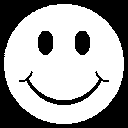

In [3]:
%pip install Pillow
from PIL import Image

smiley = Image.open("smiley.gif")
smiley

### 1.2.a. Validation du binaire

**TODO**  
À l'aide de la méthode `Image.getdata` et de la structure `set` (qui ne garde que les éléments uniques), vérifier que les pixels de l'image `smiley.gif` ne prennent que les valeurs 0 ou 1.

In [ ]:
# `getdata()` renvoie la séquence des valeurs de tous les pixels de l'image.
# `set(...)` ne garde que les valeurs uniques présentes dans cette séquence.
valeurs_uniques = set(smiley.getdata())
print(valeurs_uniques)

# Si le résultat est bien {0, 1}, chaque pixel ne prend que 2 valeurs possibles :
# on peut donc le représenter avec un seul bit (0 = noir, 1 = blanc par exemple).

### 1.2.b. Opération XOR

Le XOR est un opérateur binaire associatif et commutatif (comme AND et OR) défini par la table de vérité suivante :

| $\oplus$ | 0 | 1 |
|:--------:|:-:|:-:|
| **0**    | 0 | 1 |
| **1**    | 1 | 0 |

Autrement dit, pour un bit $b$, $b \oplus 0 = b$ et $b \oplus 1 = \neg b.$ On a aussi $b \oplus b = 0$.

En Python, cet opérateur est implémenté sur les `int` avec le symbole `^`.

**TODO**
- Grâce à la méthode `Image.putdata` et la fonction `xor`, chiffrer l'image `smiley.gif` avec la clé `key.gif`.
- Analyser le résultat :
    - Que remarque-t-on dans les bandes horizontales où la clé est noire (0) ou blanche (1) ? Est-ce le comportement attendu?
    - Dans les bandes où les pixels de la clé sont aléatoires, peut-on deviner l'image originale?

In [ ]:
def xor(a: bytes, b: bytes):
    return bytes(x ^ y for x, y in zip(a, b))


# initialise une nouvelle image avec les même paramètres (taille, palette, etc) que `smiley.gif`
cipher = smiley.copy()

key = Image.open("key.gif")

cipher.putdata(xor(bytes(smiley.getdata()), bytes(key.getdata())))
cipher

# Analyse :
# - Dans les bandes où la clé est uniformément noire (0) : b XOR 0 = b, donc le smiley
#   apparaît en clair (0 change rien). C'est attendu : une clé de 0 ne chiffre rien.
# - Dans les bandes où la clé est uniformément blanche (1) : b XOR 1 = NOT b, donc on
#   voit le smiley en négatif (couleurs inversées). C'est attendu aussi : une clé
#   constante ne fait que décaler/inverser, elle ne cache pas la structure de l'image.
# - Dans les bandes où la clé est aléatoire : les pixels deviennent eux-mêmes aléatoires,
#   on ne devine plus rien de l'image d'origine. C'est le comportement attendu d'un bon
#   masque XOR (proche d'un "one-time pad") : seule une clé vraiment aléatoire cache
#   l'information.

### 1.2.c. Appliquer le masque deux fois

**TODO**  
Chiffrer à nouveau l'image chiffrée avec la même clé. Que remarque-t-on? Est-ce le comportement attendu?

In [ ]:
decipher = cipher.copy()
decipher.putdata(xor(bytes(cipher.getdata()), bytes(key.getdata())))
decipher

# On retrouve exactement l'image d'origine (le smiley) !
# C'est attendu : b XOR k XOR k = b XOR (k XOR k) = b XOR 0 = b (le XOR est involutif).
# Chiffrer deux fois avec la même clé annule donc le chiffrement : XOR-er avec une clé
# est sa propre opération inverse (contrairement à César, pas besoin d'une fonction
# `decrypt` différente de `encrypt`).

## 1.3. Réutilisation de masque XOR

Attention à ne jamais réutiliser une clé XOR !

Dans les fichiers `cipher1.gif` ($c_1$) et `cipher2.gif` ($c_2$), nous avons deux images qui ont été XOR-ées avec le même masque.

**TODO**  
Que se voit-on si on calcule $c_1 \oplus c_2$ ?

In [ ]:
c1 = Image.open("cipher1.gif")
c2 = Image.open("cipher2.gif")

result = c1.copy()
result.putdata(xor(bytes(c1.getdata()), bytes(c2.getdata())))
result

# c1 = m1 XOR k et c2 = m2 XOR k, donc :
# c1 XOR c2 = (m1 XOR k) XOR (m2 XOR k) = m1 XOR m2 XOR (k XOR k) = m1 XOR m2
# La clé disparaît complètement ! On obtient directement le XOR des deux images en
# clair : les contours/silhouettes des deux messages originaux deviennent visibles
# (ici, un bateau viking se dessine nettement).
# => Réutiliser une même clé XOR pour plusieurs messages est une faille de sécurité
# majeure : un attaquant n'a même pas besoin de connaître la clé pour récupérer de
# l'information sur les messages en clair.

## 1.4. Bonus : Énigme

1. Déchiffrer (en XOR) le document textuel `text.enc` avec la clé `key.bin` et l'afficher en tant que texte avec la méthode `bytes.decode`.
2. À l'aide également des parties précédentes, déduire le nom de ce que ce texte représente (en 5 lettres). 
3. Utiliser ce nom comme clé pour le texte `STEZDA` dans un [chiffrement de Vigenère](https://www.dcode.fr/chiffre-vigenere) pour me communiquer le résultat. Le résultat est cohérent avec la thématique des autres indices.

In [ ]:
with open("text.enc", "rb") as f:
    data = f.read()

with open("key.bin", "rb") as f:
    key = f.read()

plain = xor(data, key)
print(plain.decode())

# `data` et `key` font la même taille (137 octets) : c'est bien un XOR simple,
# octet à octet, façon "masque jetable" (one-time pad), comme en 1.2/1.3.
# Le résultat est un dessin en art ASCII. Interprétation et déduction du mot de
# 5 lettres : voir la cellule suivante.

In [ ]:
def vigenere(text: str, key: str, encrypt: bool = True):
    """Chiffre (ou déchiffre si encrypt=False) `text` avec le chiffrement de
    Vigenère et la clé `key` (lettres non accentuées uniquement)."""
    key = key.upper()
    sign = 1 if encrypt else -1
    result = []
    for i, letter in enumerate(text):
        if letter.isalpha():
            shift = sign * (ord(key[i % len(key)]) - ord("A"))
            base = ord("A") if letter.isupper() else ord("a")
            letter = chr((ord(letter.upper()) - ord("A") + shift) % 26 + base)
        result.append(letter)
    return "".join(result)


# Le dessin ASCII obtenu ci-dessus (tête cornue, deux points pour les yeux, une
# boucle "@" évoquant une toison/corne, quatre pattes) représente un mouton/bélier
# -> en anglais "SHEEP" (5 lettres). Ça fait écho à 1.1 (L'Odyssée) : c'est en se
# cachant sous le ventre des béliers du troupeau du Cyclope Polyphème qu'Ulysse et
# ses compagnons s'échappent de la grotte.
mot = "SHEEP"

print("Vigenère(STEZDA, clé=%s) =" % mot, vigenere("STEZDA", mot, encrypt=True))

# NB : l'identification du dessin est une lecture visuelle/thématique, pas une
# certitude absolue — regardez l'image affichée ci-dessus et ajustez `mot` si vous
# identifiez autre chose, puis relancez cette cellule.

Si besoin d'aide supplémentaire, m'appeler pour que je vous donne un indice :
```hex
a19878d8fd63b462f5b43f0350c8644f062668f8691f3b2f42d611073ab2c
05fe6d18056b21f2e44c3bb5940771c353c66153724887318bc47ba6b7dca
7de59cb1c48dd871dc3ba696c73ab15be365a47adb16e7acf25d87a9c1345
4e4001bce2a8f9ccea9c0ddcc32bf010630d55ab4aa48541ec2a646630577
9d5bd85cda169bfd0398e090407cbf
```

In [ ]:
from itertools import cycle

hint_hex = (
    "a19878d8fd63b462f5b43f0350c8644f062668f8691f3b2f42d611073ab2c"
    "05fe6d18056b21f2e44c3bb5940771c353c66153724887318bc47ba6b7dca"
    "7de59cb1c48dd871dc3ba696c73ab15be365a47adb16e7acf25d87a9c1345"
    "4e4001bce2a8f9ccea9c0ddcc32bf010630d55ab4aa48541ec2a646630577"
    "9d5bd85cda169bfd0398e090407cbf"
)
hint_data = bytes.fromhex(hint_hex)

# À compléter avec la clé donnée par l'enseignant⋅e (en hexadécimal), par ex. :
# secretkey = bytes.fromhex("0a1b2c...")
secretkey = bytes.fromhex("")

if secretkey:
    # XOR avec répétition de la clé (fonctionne que la clé fasse 137 octets
    # (comme `key.bin`) ou qu'elle soit plus courte et se répète en boucle).
    hint = bytes(b ^ k for b, k in zip(hint_data, cycle(secretkey)))
    print(hint.decode(errors="replace"))
else:
    print(f"Indice chiffré ({len(hint_data)} octets) : demandez la clé à l'enseignant⋅e,"
          " puis complétez `secretkey` ci-dessus.")